In [1]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/validation.csv")

daily_df = pd.read_csv(
    "../data/processed/daily_room_demand.csv"
)

daily_df["occupied_date"] = pd.to_datetime(
    daily_df["occupied_date"]
)

val_df["occupied_date"] = pd.to_datetime(
    val_df["occupied_date"]
)

rf_model = joblib.load(
    "../backend/artifacts/random_forest_tuned.joblib"
)

xgb_model = joblib.load(
    "../backend/artifacts/xgboost_tuned.joblib"
)

TARGET = "occupied_room_nights"

FEATURES = [
    "hotel", "room_category",
    "day_of_week", "day", "month", "year",
    "quarter", "day_of_year", "is_weekend",
    "season", "lag_1", "lag_7", "lag_14",
    "lag_28", "rolling_mean_7", "rolling_mean_14",
    "rolling_mean_28", "rolling_std_7"
]

GROUP_COLS = ["hotel", "room_category"]

print("Daily data:", daily_df.shape)
print("Validation data:", val_df.shape)

Daily data: (13702, 4)
Validation data: (1989, 20)


In [22]:
def get_season(month):

    if month in [12, 1, 2]:
        return "winter"

    elif month in [3, 4, 5]:
        return "spring"

    elif month in [6, 7, 8]:
        return "summer"

    return "autumn"


def create_future_features(history, forecast_date, hotel, room_category):

    if len(history) < 28:
        raise ValueError(
            "At least 28 historical observations are required."
        )

    last_7 = history[-7:]
    last_14 = history[-14:]
    last_28 = history[-28:]

    return {
        "hotel": hotel,
        "room_category": room_category,

        "day_of_week": forecast_date.day_of_week,
        "day": forecast_date.day,
        "month": forecast_date.month,
        "year": forecast_date.year,
        "quarter": forecast_date.quarter,
        "day_of_year": forecast_date.day_of_year,
        "is_weekend": int(forecast_date.day_of_week >= 5),

        "season": get_season(forecast_date.month),

        "lag_1": history[-1],
        "lag_7": history[-7],
        "lag_14": history[-14],
        "lag_28": history[-28],

        "rolling_mean_7": np.mean(last_7),
        "rolling_mean_14": np.mean(last_14),
        "rolling_mean_28": np.mean(last_28),
        "rolling_std_7": np.std(last_7, ddof=1)
    }

In [23]:
def recursive_forecast(
    model,
    historical_data,
    forecast_dates,
    model_name
):

    predictions = []

    histories = {}

    for (hotel, room_category), group in historical_data.groupby(
        GROUP_COLS
    ):

        group = group.sort_values("occupied_date")

        histories[(hotel, room_category)] = (
            group[TARGET].astype(float).tolist()
        )

    for forecast_date in forecast_dates:

        for (hotel, room_category), history in histories.items():

            features = create_future_features(
                history,
                forecast_date,
                hotel,
                room_category
            )

            X_future = pd.DataFrame(
                [features]
            )[FEATURES]

            prediction = float(
                model.predict(X_future)[0]
            )

            prediction = max(0, prediction)

            predictions.append({
                "occupied_date": forecast_date,
                "hotel": hotel,
                "room_category": room_category,
                "model": model_name,
                "prediction": prediction
            })

            # Critical: use the prediction as future history.
            history.append(prediction)

    return pd.DataFrame(predictions)

In [24]:
def recursive_naive_forecast(
    historical_data,
    forecast_dates
):

    histories = {}

    for (hotel, room_category), group in historical_data.groupby(
        GROUP_COLS
    ):

        group = group.sort_values("occupied_date")

        histories[(hotel, room_category)] = (
            group[TARGET].astype(float).tolist()
        )

    predictions = []

    for forecast_date in forecast_dates:

        for (hotel, room_category), history in histories.items():

            prediction = max(0, history[-1])

            predictions.append({
                "occupied_date": forecast_date,
                "hotel": hotel,
                "room_category": room_category,
                "model": "Naive",
                "prediction": prediction
            })

            history.append(prediction)

    return pd.DataFrame(predictions)

In [32]:

def evaluate_recursive_forecasts(horizon, step, evaluation_df):

    evaluation_dates = sorted(
        evaluation_df["occupied_date"].unique()
    )

    all_predictions = []

    for start_idx in range(
        0,
        len(evaluation_dates) - horizon + 1,
        step
    ):

        forecast_dates = evaluation_dates[
            start_idx:start_idx + horizon
        ]

        origin_date = (
            pd.Timestamp(forecast_dates[0])
            - pd.Timedelta(days=1)
        )

        # Only observations available before the forecast origin.
        historical_data = daily_df[
            daily_df["occupied_date"] <= origin_date
        ].copy()

        rf_predictions = recursive_forecast(
            rf_model,
            historical_data,
            forecast_dates,
            "Random Forest"
        )

        xgb_predictions = recursive_forecast(
            xgb_model,
            historical_data,
            forecast_dates,
            "XGBoost"
        )

        naive_predictions = recursive_naive_forecast(
            historical_data,
            forecast_dates
        )

        all_predictions.extend([
            rf_predictions,
            xgb_predictions,
            naive_predictions
        ])

    if not all_predictions:
        raise ValueError(
            f"Not enough dates to evaluate a {horizon}-day forecast."
        )

    return pd.concat(
        all_predictions,
        ignore_index=True
    )


In [33]:
predictions_7d = evaluate_recursive_forecasts(
    horizon=7,
    step=7,
    evaluation_df=val_df
)

predictions_14d = evaluate_recursive_forecasts(
    horizon=14,
    step=14,
    evaluation_df=val_df
)

In [34]:
def calculate_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.abs(actual - predicted).sum()
        / np.abs(actual).sum()
        * 100
    )

    return {
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "WAPE (%)": round(wape, 3)
    }


def compare_forecasts(predictions, actual_df):

    comparison = predictions.merge(
        actual_df[
            [
                "occupied_date",
                "hotel",
                "room_category",
                TARGET
            ]
        ],
        on=[
            "occupied_date",
            "hotel",
            "room_category"
        ],
        how="inner"
    )

    results = []

    for model_name, group in comparison.groupby("model"):

        metrics = calculate_metrics(
            group[TARGET],
            group["prediction"]
        )

        results.append({
            "Model": model_name,
            **metrics
        })

    return pd.DataFrame(results).sort_values("MAE"), comparison

In [35]:
results_7d, comparison_7d = compare_forecasts(
    predictions_7d,
    val_df
)

results_14d, comparison_14d = compare_forecasts(
    predictions_14d,
    val_df
)

print("7-DAY FORECAST RESULTS")
display(results_7d)

print("14-DAY FORECAST RESULTS")
display(results_14d)


7-DAY FORECAST RESULTS


,Model,MAE,RMSE,WAPE (%)
2,XGBoost,3.140,6.038,18.147
1,Random Forest,3.193,6.392,18.450
0,Naive,3.384,6.809,19.556


14-DAY FORECAST RESULTS


,Model,MAE,RMSE,WAPE (%)
0,Naive,3.289,6.235,19.007
1,Random Forest,3.383,6.734,19.553
2,XGBoost,3.407,6.577,19.689


In [36]:
comparison_14d["absolute_error"] = np.abs(
    comparison_14d[TARGET]
    - comparison_14d["prediction"]
)

hotel_errors = (
    comparison_14d
    .groupby(["model", "hotel"])["absolute_error"]
    .mean()
    .reset_index(name="MAE")
)

room_errors = (
    comparison_14d
    .groupby(["model", "room_category"])["absolute_error"]
    .mean()
    .reset_index(name="MAE")
)

print("Error by hotel:")
display(hotel_errors)

print("Error by room category:")
display(room_errors)

Error by hotel:


,model,hotel,MAE
0,Naive,City Hotel,3.600446
1,Naive,Resort Hotel,3.011905
2,Random Forest,City Hotel,3.975967
3,Random Forest,Resort Hotel,2.856772
4,XGBoost,City Hotel,3.824584
5,XGBoost,Resort Hotel,3.035492


Error by room category:


,model,room_category,MAE
0,Naive,A,10.441964
1,Naive,B,0.616071
2,Naive,C,1.254464
3,Naive,D,7.102679
4,Naive,E,3.352679
5,Naive,F,1.937500
6,Naive,G,1.683036
7,Naive,H,1.053571
8,Naive,I,1.098214
9,Naive,K,0.982143


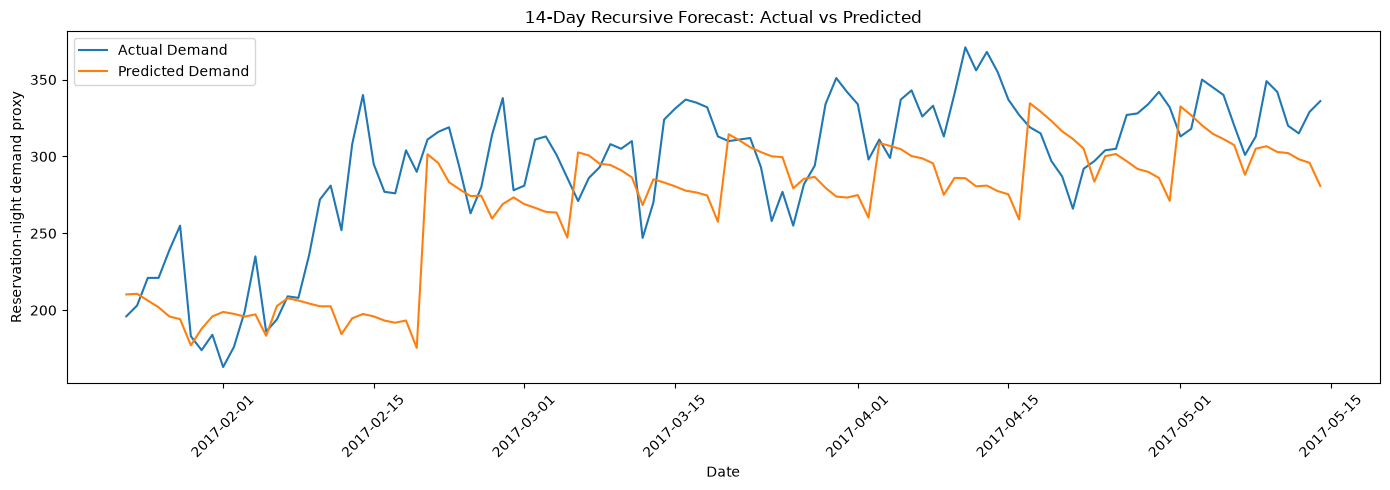

In [37]:
import matplotlib.pyplot as plt

model_to_plot = "XGBoost"

plot_df = comparison_14d[
    comparison_14d["model"] == model_to_plot
]

daily_comparison = (
    plot_df
    .groupby("occupied_date")[
        [TARGET, "prediction"]
    ]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_comparison["occupied_date"],
    daily_comparison[TARGET],
    label="Actual Demand"
)

plt.plot(
    daily_comparison["occupied_date"],
    daily_comparison["prediction"],
    label="Predicted Demand"
)

plt.title("14-Day Recursive Forecast: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Reservation-night demand proxy")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
from pathlib import Path

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(exist_ok=True)

results_7d.to_csv(
    REPORT_DIR / "day6_7day_forecast_metrics.csv",
    index=False
)

results_14d.to_csv(
    REPORT_DIR / "day6_14day_forecast_metrics.csv",
    index=False
)

comparison_7d.to_csv(
    REPORT_DIR / "day6_7day_predictions.csv",
    index=False
)

comparison_14d.to_csv(
    REPORT_DIR / "day6_14day_predictions.csv",
    index=False
)

print("Day 6 results saved successfully.")


Day 6 results saved successfully.


In [41]:
test_df = pd.read_csv(
    "../data/processed/test.csv"
)

test_df["occupied_date"] = pd.to_datetime(
    test_df["occupied_date"]
)

test_df = test_df.sort_values(
    ["hotel", "room_category", "occupied_date"]
).reset_index(drop=True)

print("Test dataset shape:", test_df.shape)
print(
    "Test date range:",
    test_df["occupied_date"].min(),
    "to",
    test_df["occupied_date"].max()
)

display(test_df.head())

Test dataset shape: (1989, 20)
Test date range: 2017-05-20 00:00:00 to 2017-09-13 00:00:00


,occupied_date,hotel,room_category,occupied_room_nights,day_of_week,day,month,year,quarter,day_of_year,is_weekend,season,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28,rolling_std_7
0,2017-05-20,City Hotel,A,120.0,5,20,5,2017,2,140,1,Spring,118.0,109.0,112.0,75.0,113.000000,113.357143,111.392857,3.464102
1,2017-05-21,City Hotel,A,123.0,6,21,5,2017,2,141,1,Spring,120.0,110.0,107.0,91.0,114.571429,113.928571,113.000000,3.823486
2,2017-05-22,City Hotel,A,110.0,0,22,5,2017,2,142,0,Spring,123.0,112.0,112.0,104.0,116.428571,115.071429,114.142857,4.353433
3,2017-05-23,City Hotel,A,109.0,1,23,5,2017,2,143,0,Spring,110.0,117.0,128.0,103.0,116.142857,114.928571,114.357143,4.740906
4,2017-05-24,City Hotel,A,100.0,2,24,5,2017,2,144,0,Spring,109.0,111.0,127.0,112.0,115.000000,113.571429,114.571429,5.416026


In [43]:
print("Missing values:")
print(test_df.isnull().sum())

print("\nUnique hotels:")
print(test_df["hotel"].unique())

print("\nUnique room categories:")
print(test_df["room_category"].unique())

Missing values:
occupied_date           0
hotel                   0
room_category           0
occupied_room_nights    0
day_of_week             0
day                     0
month                   0
year                    0
quarter                 0
day_of_year             0
is_weekend              0
season                  0
lag_1                   0
lag_7                   0
lag_14                  0
lag_28                  0
rolling_mean_7          0
rolling_mean_14         0
rolling_mean_28         0
rolling_std_7           0
dtype: int64

Unique hotels:
<StringArray>
['City Hotel', 'Resort Hotel']
Length: 2, dtype: str

Unique room categories:
<StringArray>
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'K', 'H', 'I']
Length: 10, dtype: str


In [44]:
test_predictions_7d = evaluate_recursive_forecasts(
    horizon=7,
    step=7,
    evaluation_df=test_df
)

test_predictions_14d = evaluate_recursive_forecasts(
    horizon=14,
    step=14,
    evaluation_df=test_df
)

print("7-day predictions:", test_predictions_7d.shape)
print("14-day predictions:", test_predictions_14d.shape)

7-day predictions: (5712, 5)
14-day predictions: (5712, 5)


In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd


def calculate_forecast_metrics(predictions, evaluation_df):

    actual_data = evaluation_df[
        ["occupied_date", "hotel", "room_category", TARGET]
    ].copy()

    results = predictions.merge(
        actual_data,
        on=["occupied_date", "hotel", "room_category"],
        how="left",
        validate="many_to_one"
    )

    if results[TARGET].isna().any():
        raise ValueError(
            "Some predictions do not have matching actual values."
        )

    metrics = []

    for model_name, group in results.groupby("model"):

        actual = group[TARGET].to_numpy()
        predicted = group["prediction"].to_numpy()

        mae = mean_absolute_error(actual, predicted)

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        total_actual = np.abs(actual).sum()

        wape = (
            np.abs(actual - predicted).sum() / total_actual * 100
            if total_actual > 0
            else np.nan
        )

        metrics.append({
            "Model": model_name,
            "MAE": round(mae, 3),
            "RMSE": round(rmse, 3),
            "WAPE (%)": round(wape, 3)
        })

    return pd.DataFrame(metrics).sort_values("MAE")

In [47]:
test_metrics_7d = calculate_forecast_metrics(
    test_predictions_7d,
    test_df
)

test_metrics_14d = calculate_forecast_metrics(
    test_predictions_14d,
    test_df
)


print("FINAL 7-DAY TEST RESULTS")

display(test_metrics_7d)

print("FINAL 14-DAY TEST RESULTS")
display(test_metrics_14d)

FINAL 7-DAY TEST RESULTS


,Model,MAE,RMSE,WAPE (%)
0,Naive,2.619,7.463,13.231
1,Random Forest,3.026,8.343,15.287
2,XGBoost,3.160,8.253,15.966


FINAL 14-DAY TEST RESULTS


,Model,MAE,RMSE,WAPE (%)
0,Naive,3.147,9.102,15.898
1,Random Forest,3.393,9.481,17.143
2,XGBoost,3.578,9.323,18.078


In [48]:

def prepare_error_analysis(predictions, evaluation_df):

    actual_data = evaluation_df[
        ["occupied_date", "hotel", "room_category", TARGET]
    ].copy()

    results = predictions.merge(
        actual_data,
        on=["occupied_date", "hotel", "room_category"],
        how="left",
        validate="many_to_one"
    )

    results["error"] = (
        results["prediction"] - results[TARGET]
    )

    results["absolute_error"] = results["error"].abs()

    return results


error_7d = prepare_error_analysis(
    test_predictions_7d, test_df
)

error_14d = prepare_error_analysis(
    test_predictions_14d, test_df
)


In [49]:
hotel_errors = (
    error_7d.groupby(["model", "hotel"])
    .agg(
        MAE=("absolute_error", "mean"),
        Average_Error=("error", "mean"),
        Observations=("error", "size")
    )
    .reset_index()
)

display(hotel_errors.round(3))

,model,hotel,MAE,Average_Error,Observations
0,Naive,City Hotel,3.426,0.609,896
1,Naive,Resort Hotel,1.901,0.732,1008
2,Random Forest,City Hotel,4.268,-0.638,896
3,Random Forest,Resort Hotel,1.921,0.578,1008
4,XGBoost,City Hotel,4.310,-0.707,896
5,XGBoost,Resort Hotel,2.138,0.055,1008


In [50]:
room_errors = (
    error_7d.groupby(["model", "room_category"])
    .agg(
        MAE=("absolute_error", "mean"),
        Average_Error=("error", "mean"),
        Observations=("error", "size")
    )
    .reset_index()
    .sort_values(
        ["model", "MAE"],
        ascending=[True, False]
    )
)

display(room_errors.round(3))

,model,room_category,MAE,Average_Error,Observations
0,Naive,A,11.232,2.670,224
3,Naive,D,4.241,1.580,224
4,Naive,E,2.098,0.241,224
8,Naive,I,1.250,-0.143,112
5,Naive,F,1.134,0.545,224
6,Naive,G,1.112,0.299,224
2,Naive,C,0.911,0.375,224
9,Naive,K,0.786,-0.071,112
7,Naive,H,0.429,0.214,112
1,Naive,B,0.299,0.022,224


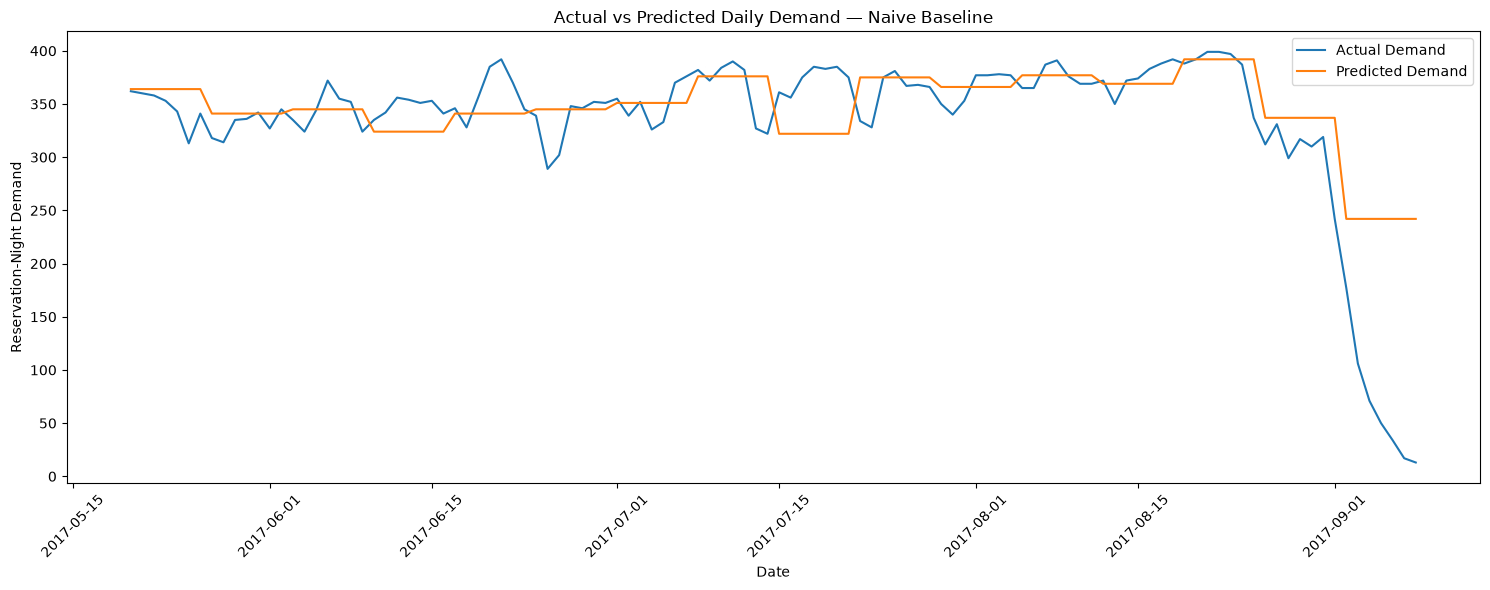

In [51]:
import matplotlib.pyplot as plt

model_to_plot = "Naive"

plot_data = error_7d[
    error_7d["model"] == model_to_plot
]

daily_comparison = (
    plot_data.groupby("occupied_date")
    .agg(
        Actual=(TARGET, "sum"),
        Predicted=("prediction", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(15, 6))

plt.plot(
    daily_comparison["occupied_date"],
    daily_comparison["Actual"],
    label="Actual Demand"
)

plt.plot(
    daily_comparison["occupied_date"],
    daily_comparison["Predicted"],
    label="Predicted Demand"
)

plt.title("Actual vs Predicted Daily Demand — Naive Baseline")
plt.xlabel("Date")
plt.ylabel("Reservation-Night Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
from pathlib import Path

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

hotel_errors.to_csv(
    reports_dir / "test_error_by_hotel.csv",
    index=False
)

room_errors.to_csv(
    reports_dir / "test_error_by_room_category.csv",
    index=False
)

error_7d.to_csv(
    reports_dir / "test_error_analysis_7d.csv",
    index=False
)

error_14d.to_csv(
    reports_dir / "test_error_analysis_14d.csv",
    index=False
)

In [53]:
print("Room categories in test data:")
print(test_df["room_category"].value_counts(dropna=False))

print("\nRoom categories in 7-day error data:")
print(error_7d[
    error_7d["model"] == "Naive"
]["room_category"].value_counts(dropna=False))

print("\nTotal observations by model:")
print(error_7d.groupby("model").size())

Room categories in test data:
room_category
A    234
B    234
C    234
D    234
E    234
F    234
G    234
K    117
H    117
I    117
Name: count, dtype: int64

Room categories in 7-day error data:
room_category
A    224
B    224
C    224
D    224
E    224
F    224
G    224
K    112
H    112
I    112
Name: count, dtype: int64

Total observations by model:
model
Naive            1904
Random Forest    1904
XGBoost          1904
dtype: int64


In [54]:
def category_error_metrics(error_data):

    results = []

    for (model, category), group in error_data.groupby(
        ["model", "room_category"]
    ):

        actual = group[TARGET].to_numpy()
        predicted = group["prediction"].to_numpy()

        total_actual = np.abs(actual).sum()

        wape = (
            np.abs(actual - predicted).sum() / total_actual * 100
            if total_actual > 0
            else np.nan
        )

        results.append({
            "Model": model,
            "Room Category": category,
            "MAE": np.abs(actual - predicted).mean(),
            "WAPE (%)": wape,
            "Bias": (predicted - actual).mean(),
            "Actual Demand": actual.sum(),
            "Observations": len(group)
        })

    return pd.DataFrame(results).round(3)


category_metrics = category_error_metrics(error_7d)

display(
    category_metrics.sort_values(
        ["Model", "WAPE (%)"],
        ascending=[True, False]
    )
)

,Model,Room Category,MAE,WAPE (%),Bias,Actual Demand,Observations
9,Naive,K,0.786,123.944,-0.071,71.0,112
8,Naive,I,1.250,66.038,-0.143,212.0,112
1,Naive,B,0.299,25.000,0.022,268.0,224
6,Naive,G,1.112,22.595,0.299,1102.0,224
7,Naive,H,0.429,16.901,0.214,284.0,112
2,Naive,C,0.911,16.653,0.375,1225.0,224
5,Naive,F,1.134,15.806,0.545,1607.0,224
0,Naive,A,11.232,13.364,2.670,18827.0,224
4,Naive,E,2.098,12.048,0.241,3901.0,224
3,Naive,D,4.241,9.325,1.580,10188.0,224


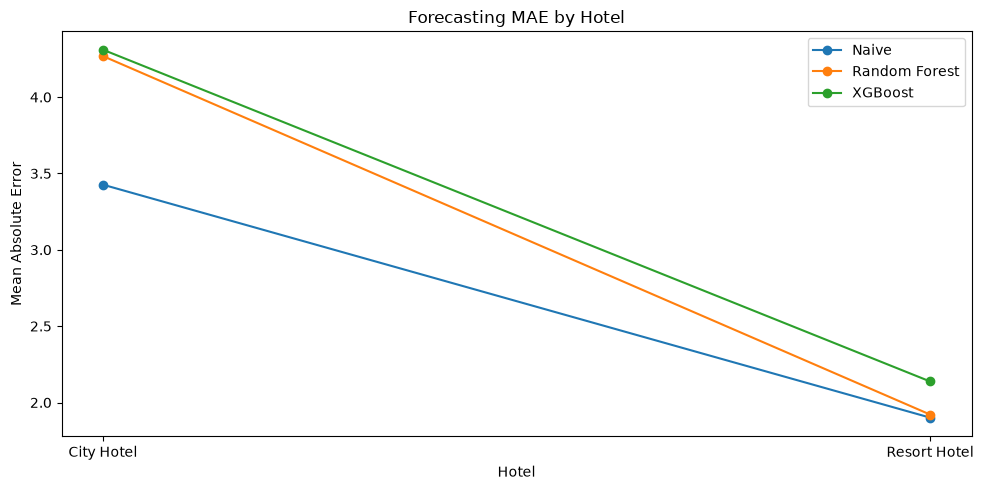

In [55]:
hotel_plot = (
    error_7d.groupby(["model", "hotel"])["absolute_error"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

for model in hotel_plot["model"].unique():
    subset = hotel_plot[hotel_plot["model"] == model]

    plt.plot(
        subset["hotel"],
        subset["absolute_error"],
        marker="o",
        label=model
    )

plt.title("Forecasting MAE by Hotel")
plt.xlabel("Hotel")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
from pathlib import Path
import pandas as pd

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Combine test metrics
final_comparison = pd.concat([
    test_metrics_7d.assign(Horizon="7-day"),
    test_metrics_14d.assign(Horizon="14-day")
], ignore_index=True)

final_comparison = final_comparison[
    ["Horizon", "Model", "MAE", "RMSE", "WAPE (%)"]
]

final_comparison.to_csv(
    reports_dir / "final_test_model_comparison.csv",
    index=False
)

category_metrics.to_csv(
    reports_dir / "test_category_metrics_7d.csv",
    index=False
)

hotel_errors.to_csv(
    reports_dir / "test_hotel_error_analysis_7d.csv",
    index=False
)

print("Final evaluation reports saved successfully.")
display(final_comparison)

Final evaluation reports saved successfully.


,Horizon,Model,MAE,RMSE,WAPE (%)
0,7-day,Naive,2.619,7.463,13.231
1,7-day,Random Forest,3.026,8.343,15.287
2,7-day,XGBoost,3.160,8.253,15.966
3,14-day,Naive,3.147,9.102,15.898
4,14-day,Random Forest,3.393,9.481,17.143
5,14-day,XGBoost,3.578,9.323,18.078
